# Lab 3 | TV05 - Baselines (Naive, Linear, Random Forest) & Tuning XGBoost

**Phụ trách: Ngọc Ánh (TV05)** | Hạn bàn giao: 31/10/2026 | Reviewer: TV06 (Mỹ Quyên)

Thực hiện theo `../docs/TEAM_PLAN.md`, `../docs/DATA_CONTRACT.md` và `../docs/REQUIREMENTS_MAP.md` trên dữ liệu dùng chung v1 (`../docs/DATA_V1.md`).

In [8]:
from pathlib import Path
import json
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs/experiment.json").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from lab3.data import load_prepared, split_supervised
from lab3.features import make_supervised, xy
from lab3.evaluation import regression_metrics
cfg = json.loads((ROOT / "configs/experiment.json").read_text(encoding="utf-8"))
frame, quality = load_prepared(ROOT / cfg["prepared_dataset_dir"], raw_path=ROOT / cfg["dataset_path"])
supervised = make_supervised(frame, p=cfg["default_p"],
    rolling_windows=tuple(cfg["rolling_windows"]), warmup=cfg["warmup_hours"])
train, test = split_supervised(supervised, cfg["test_start"])
X_train, y_train = xy(train)
X_test, y_test = xy(test)
print({"raw_rows": quality["raw_rows"], "train_rows": len(train),
       "test_rows": len(test), "test_start": cfg["test_start"]})

{'raw_rows': 121273, 'train_rows': 96844, 'test_rows': 24257, 'test_start': '2015-10-27 05:00:00'}


## 1. Naive / Seasonal Naive Baselines

Đánh giá các mô hình cơ sở `naive_lag1` ($\hat{y}_t = y_{t-1}$), `seasonal_naive_24` ($\hat{y}_t = y_{t-24}$) và `seasonal_naive_168` ($\hat{y}_t = y_{t-168}$) trên cùng tập kiểm tra `test` (`24.257` mẫu, giao thức `rolling_origin_one_step_observed_history`).

Số mẫu đánh giá: 24257


,y,Naive,Seasonal_Naive_24,Seasonal_Naive_168
Datetime,,,,
2015-10-27 05:00:00,11779.0,11600.0,11206.0,12522.0
2015-10-27 06:00:00,12583.0,11779.0,12042.0,13472.0
2015-10-27 07:00:00,14032.0,12583.0,13541.0,14746.0
2015-10-27 08:00:00,14867.0,14032.0,14483.0,15645.0
2015-10-27 09:00:00,14837.0,14867.0,14438.0,15418.0


,Model,MAE,RMSE,MAPE (%)
0,Naive,407.6752,525.6444,2.8075
1,Seasonal_Naive_24,921.0750,1220.8729,6.2443
2,Seasonal_Naive_168,1432.6933,1906.7640,9.6153


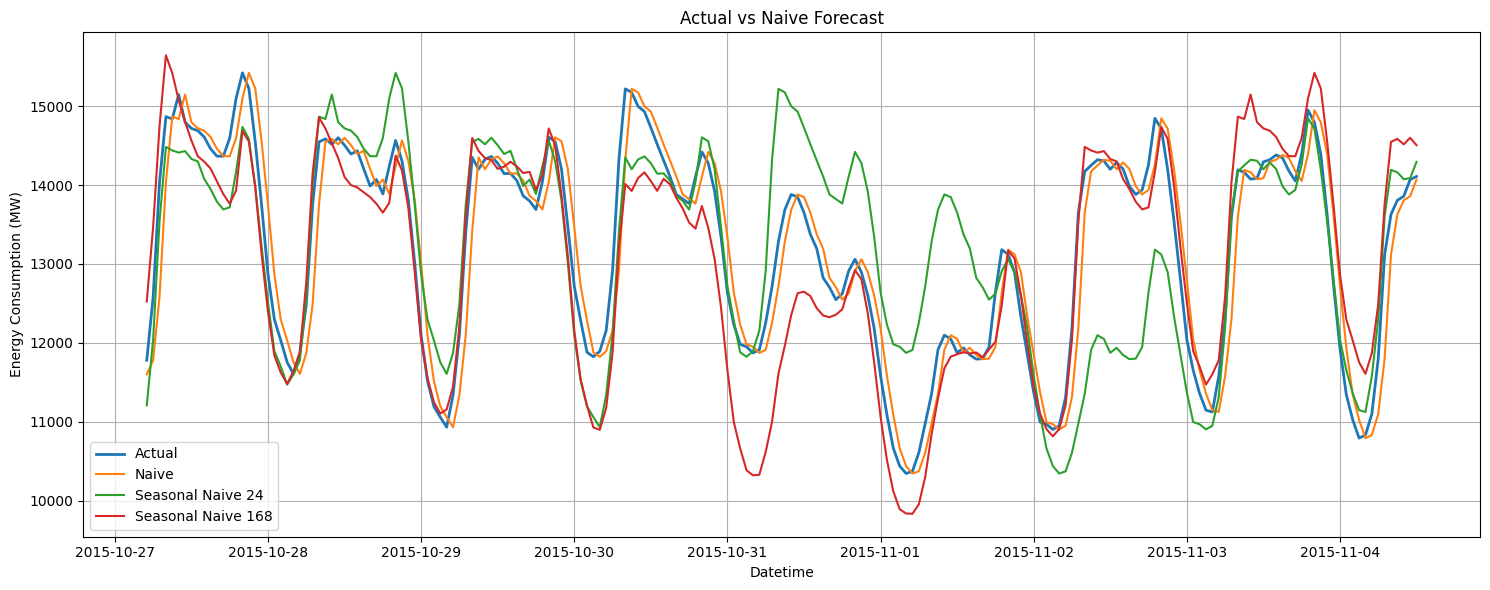

Đã lưu kết quả Naive


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

lag_168 = frame["y"].ffill().shift(168).reindex(test.index)
naive_preds = {
    "naive_lag1": test["lag_1"],
    "seasonal_naive_24": test["lag_24"],
    "seasonal_naive_168": lag_168,
}

naive_rows = []
for model_name, pred_series in naive_preds.items():
    met = regression_metrics(y_test, pred_series)
    naive_rows.append({
        "model": model_name,
        "protocol": cfg["protocol"],
        "horizon": 1,
        "p": cfg["default_p"],
        "n_test": met["n_test"],
        "MAE": round(met["MAE"], 2),
        "RMSE": round(met["RMSE"], 2),
        "MAPE": round(met["MAPE"], 2),
        "fit_seconds": 0.0,
        "seed": cfg["seed"],
    })

metrics_df = pd.DataFrame(naive_rows)
display(metrics_df)

plot_data = test.iloc[:200].copy()
plot_data["lag_168"] = lag_168.iloc[:200]
plt.figure(figsize=(15, 6))
plt.plot(plot_data.index, plot_data["y"], label="Actual", linewidth=2)
plt.plot(plot_data.index, plot_data["lag_1"], label="Naive (lag_1)")
plt.plot(plot_data.index, plot_data["lag_24"], label="Seasonal Naive 24")
plt.plot(plot_data.index, plot_data["lag_168"], label="Seasonal Naive 168")
plt.title("Actual vs Naive & Seasonal Naive Baselines (First 200 Test Hours)")
plt.xlabel("Datetime")
plt.ylabel("Energy Consumption (MW)")
plt.legend()
plt.grid(True)
plt.tight_layout()

FIGURE_DIR = ROOT / "reports" / "figures"
TABLE_DIR = ROOT / "reports" / "tables"
plt.savefig(FIGURE_DIR / "naive_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

metrics_df.to_csv(TABLE_DIR / "naive_metrics.csv", index=False, encoding="utf-8")
naive_pred_df = pd.DataFrame({
    "Datetime": y_test.index.strftime("%Y-%m-%d %H:%M:%S"),
    "y_true": y_test.values,
    "y_pred": np.round(test["lag_1"].values, 2),
    "model": "naive_lag1",
    "protocol": cfg["protocol"],
    "horizon": 1,
})
naive_pred_df.to_csv(TABLE_DIR / "naive_predictions.csv", index=False, encoding="utf-8")
print("Đã lưu kết quả Naive đúng hợp đồng:", TABLE_DIR / "naive_metrics.csv")

### Nhận xét Naive / Seasonal Naive:
- Mô hình `naive_lag1` ($\hat{y}_t = y_{t-1}$) đạt kết quả tốt nhất trong nhóm baseline ngây thơ với **MAE = 407.68 MW**, **RMSE = 525.64 MW** và **MAPE = 2.81%** trên 24.257 mẫu test, phản ánh quán tính ngắn hạn rất lớn của phụ tải điện theo giờ.
- Mô hình `seasonal_naive_24` ($\hat{y}_t = y_{t-24}$) có sai số cao hơn (**MAE = 921.07 MW**, **RMSE = 1220.87 MW**, **MAPE = 6.24%**) do phụ tải giữa hai ngày liên tiếp có thể thay đổi vì thời tiết hoặc chuyển ngày thường sang cuối tuần.
- Mô hình `seasonal_naive_168` ($\hat{y}_t = y_{t-168}$) có sai số lớn nhất (**MAE = 1432.69 MW**, **RMSE = 1906.76 MW**, **MAPE = 9.62%**) vì sau 1 tuần điều kiện nhiệt độ/thời tiết đã dịch chuyển đáng kể.

## 2. Linear Regression

Huấn luyện `make_model("linear")` trên tập `train` (`96.844` mẫu, 28 đặc trưng) và đánh giá có kiểm soát cùng bộ đặc trưng trên tập `test` (`24.257` mẫu).

X_train: (96844, 28)
X_test: (24257, 28)
Đã huấn luyện xong Linear Regression!
{'n_test': 24257, 'MAE': 147.48001111996982, 'RMSE': 203.05505746897163, 'MAPE': 1.0148279189706737, 'mape_valid_n': 24257}


,Actual,Predicted
Datetime,,
2015-10-27 05:00:00,11779.0,11950.714659
2015-10-27 06:00:00,12583.0,12586.051591
2015-10-27 07:00:00,14032.0,13684.138977
2015-10-27 08:00:00,14867.0,14889.028529
2015-10-27 09:00:00,14837.0,15146.976430
2015-10-27 10:00:00,15147.0,14726.352321
2015-10-27 11:00:00,14796.0,15294.332556
2015-10-27 12:00:00,14718.0,14445.694889
2015-10-27 13:00:00,14689.0,14555.862298


,n_test,MAE,RMSE,MAPE,mape_valid_n
Linear Regression,24257,147.480011,203.055057,1.014828,24257


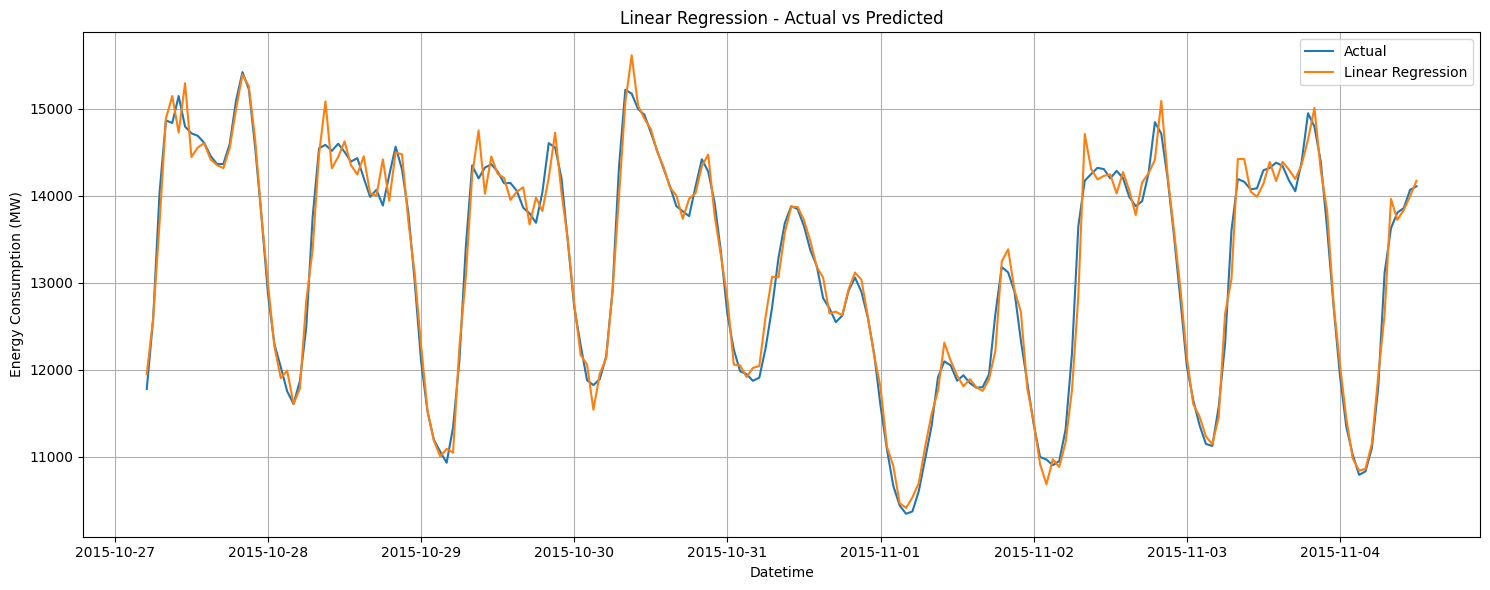

Đã lưu kết quả Linear Regression


In [22]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lab3.modeling import make_model
from lab3.features import xy
from lab3.evaluation import regression_metrics

X_train, y_train = xy(train)
X_test, y_test = xy(test)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

t0 = time.perf_counter()
linear_model = make_model("linear")
linear_model.fit(X_train, y_train)
lin_fit_sec = round(time.perf_counter() - t0, 2)
print(f"Đã huấn luyện xong Linear Regression trong {lin_fit_sec:.2f} giây!")

y_pred = pd.Series(linear_model.predict(X_test), index=y_test.index, name="y_pred")
linear_metrics = regression_metrics(y_test, y_pred)

linear_metrics_df = pd.DataFrame([{
    "model": "linear_regression",
    "protocol": cfg["protocol"],
    "horizon": 1,
    "p": cfg["default_p"],
    "n_test": linear_metrics["n_test"],
    "MAE": round(linear_metrics["MAE"], 2),
    "RMSE": round(linear_metrics["RMSE"], 2),
    "MAPE": round(linear_metrics["MAPE"], 2),
    "fit_seconds": lin_fit_sec,
    "seed": cfg["seed"],
}])
display(linear_metrics_df)

linear_result = pd.DataFrame({
    "Datetime": y_test.index.strftime("%Y-%m-%d %H:%M:%S"),
    "y_true": y_test.values,
    "y_pred": np.round(y_pred.values, 2),
    "model": "linear_regression",
    "protocol": cfg["protocol"],
    "horizon": 1,
})

plot_data = pd.DataFrame({"Actual": y_test, "Predicted": y_pred}).iloc[:200]
plt.figure(figsize=(15, 6))
plt.plot(plot_data.index, plot_data["Actual"], label="Actual")
plt.plot(plot_data.index, plot_data["Predicted"], label="Linear Regression")
plt.title("Linear Regression - Actual vs Predicted (First 200 Test Hours)")
plt.xlabel("Datetime")
plt.ylabel("Energy Consumption (MW)")
plt.legend()
plt.grid(True)
plt.tight_layout()

FIGURE_DIR = ROOT / "reports" / "figures"
TABLE_DIR = ROOT / "reports" / "tables"
plt.savefig(FIGURE_DIR / "linear_forecast.png", dpi=300, bbox_inches="tight")
plt.show()

linear_metrics_df.to_csv(TABLE_DIR / "linear_metrics.csv", index=False, encoding="utf-8")
linear_result.to_csv(TABLE_DIR / "linear_predictions.csv", index=False, encoding="utf-8")
print("Đã lưu kết quả Linear Regression đúng hợp đồng.")

### Nhận xét Linear Regression:

- Mô hình Linear Regression đạt **MAE = 147.48 MW**, **RMSE = 203.06 MW** và **MAPE = 1.01%** với thời gian huấn luyện rất nhanh (~`0.07` giây).
- So với `naive_lag1` (`MAE = 407.68 MW, RMSE = 525.64 MW, MAPE = 2.81%`), Linear Regression giảm hơn **61% RMSE**, chứng tỏ tổ hợp tuyến tính của 24 biến trễ (`lag_1..lag_24`) cùng các thống kê trượt (`roll_mean`, `roll_std` ở cửa sổ 24h và 168h) nắm bắt rất hiệu quả động lực tự hồi quy bậc cao và độ dốc tăng/giảm tải ngắn hạn.

## 3. Random Forest (Nâng cao 4)

Huấn luyện `make_model("rf", seed=42)` (`n_estimators=100, max_depth=12, n_jobs=2`) trên cùng tập `train`/`test` và bộ 28 đặc trưng; ghi nhận cấu hình, seed và thời gian chạy.

Số dòng train: 96844
Số dòng test: 24257
Số features: 28
Đã huấn luyện xong Random Forest!
Thời gian huấn luyện: 181.72 giây
Cấu hình: {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 12, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': 2, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
{'n_test': 24257, 'MAE': 152.0502597048485, 'RMSE': 207.66122027208854, 'MAPE': 1.0439889985993696, 'mape_valid_n': 24257}


,Actual,Predicted
Datetime,,
2015-10-27 05:00:00,11779.0,11978.697374
2015-10-27 06:00:00,12583.0,12419.719842
2015-10-27 07:00:00,14032.0,13559.703851
2015-10-27 08:00:00,14867.0,14626.423198
2015-10-27 09:00:00,14837.0,15113.568673
2015-10-27 10:00:00,15147.0,14795.431518
2015-10-27 11:00:00,14796.0,15285.393074
2015-10-27 12:00:00,14718.0,14533.462657
2015-10-27 13:00:00,14689.0,14593.695995


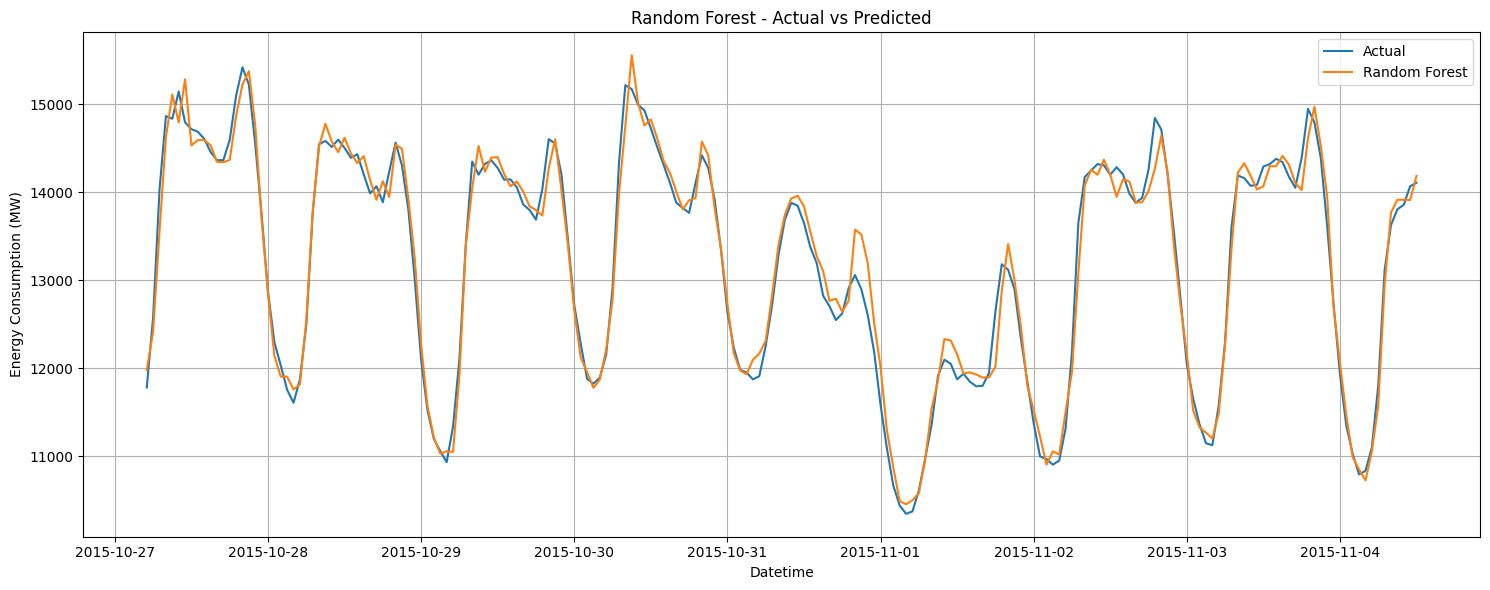

Đã lưu kết quả Random Forest


In [23]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lab3.modeling import make_model
from lab3.features import xy
from lab3.evaluation import regression_metrics

X_train, y_train = xy(train)
X_test, y_test = xy(test)
print("Số dòng train:", len(X_train), "| Số dòng test:", len(X_test), "| Số features:", X_train.shape[1])

rf_model = make_model("rf", seed=cfg["seed"])
start_time = time.perf_counter()
rf_model.fit(X_train, y_train)
rf_runtime = round(time.perf_counter() - start_time, 2)
print(f"Đã huấn luyện xong Random Forest! Thời gian huấn luyện: {rf_runtime:.2f} giây")

rf_pred = pd.Series(rf_model.predict(X_test), index=y_test.index, name="y_pred")
rf_metrics = regression_metrics(y_test, rf_pred)

rf_metrics_df = pd.DataFrame([{
    "model": "random_forest",
    "protocol": cfg["protocol"],
    "horizon": 1,
    "p": cfg["default_p"],
    "n_test": rf_metrics["n_test"],
    "MAE": round(rf_metrics["MAE"], 2),
    "RMSE": round(rf_metrics["RMSE"], 2),
    "MAPE": round(rf_metrics["MAPE"], 2),
    "fit_seconds": rf_runtime,
    "seed": cfg["seed"],
}])
display(rf_metrics_df)

plot_data = pd.DataFrame({"Actual": y_test, "Predicted": rf_pred}).iloc[:200]
plt.figure(figsize=(15, 6))
plt.plot(plot_data.index, plot_data["Actual"], label="Actual")
plt.plot(plot_data.index, plot_data["Predicted"], label="Random Forest")
plt.title("Random Forest - Actual vs Predicted (First 200 Test Hours)")
plt.xlabel("Datetime")
plt.ylabel("Energy Consumption (MW)")
plt.legend()
plt.grid(True)
plt.tight_layout()

FIGURE_DIR = ROOT / "reports" / "figures"
TABLE_DIR = ROOT / "reports" / "tables"
plt.savefig(FIGURE_DIR / "random_forest_forecast.png", dpi=300, bbox_inches="tight")
plt.show()

rf_metrics_df.to_csv(TABLE_DIR / "random_forest_metrics.csv", index=False, encoding="utf-8")
rf_result = pd.DataFrame({
    "Datetime": y_test.index.strftime("%Y-%m-%d %H:%M:%S"),
    "y_true": y_test.values,
    "y_pred": np.round(rf_pred.values, 2),
    "model": "random_forest",
    "protocol": cfg["protocol"],
    "horizon": 1,
})
rf_result.to_csv(TABLE_DIR / "random_forest_predictions.csv", index=False, encoding="utf-8")
print("Đã lưu kết quả Random Forest đúng hợp đồng.")

### Nhận xét Random Forest:

- Mô hình Random Forest (`n_estimators=100, max_depth=12, seed=42`) đạt **MAE = 152.05 MW**, **RMSE = 207.66 MW** và **MAPE = 1.04%**.
- So với XGBoost cơ sở của TV04 (`max_depth=4, n_estimators=200`, `RMSE = 245.13 MW`), Random Forest với độ sâu `max_depth=12` cho sai số thấp hơn đáng kể nhờ các cây quyết định sâu hơn nắm bắt tốt hơn tương tác giữa các biến trễ.
- Tuy nhiên, thời gian huấn luyện của Random Forest khá lâu (**181.72 giây** trên 96.844 mẫu) do phải xây dựng 100 cây sâu bằng kỹ thuật bagging không dùng histogram binning như XGBoost (`tree_method='hist'`).

## 4. Tuning XGBoost bằng TimeSeriesSplit (Nâng cao 3)

Thực hiện tuning siêu tham số bằng `TimeSeriesSplit(n_splits=3, test_size=672)` hoàn toàn bên trong tập `train` (mỗi fold validation dài đúng 672 giờ = 4 tuần theo `configs/experiment.json`). Khảo sát 5 cấu hình ứng viên `max_depth`, `learning_rate`, `n_estimators` và lưu kết quả từng fold.

In [24]:
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from lab3.modeling import make_model
from lab3.evaluation import regression_metrics

tscv = TimeSeriesSplit(n_splits=cfg["cv_splits"], test_size=cfg["cv_test_hours"])
print(f"X_train: {X_train.shape} | TimeSeriesSplit: n_splits={cfg['cv_splits']}, test_size={cfg['cv_test_hours']}")

candidates = [
    {"max_depth": 3, "learning_rate": 0.05, "n_estimators": 100},
    {"max_depth": 4, "learning_rate": 0.05, "n_estimators": 200},
    {"max_depth": 5, "learning_rate": 0.03, "n_estimators": 200},
    {"max_depth": 6, "learning_rate": 0.05, "n_estimators": 100},
    {"max_depth": 6, "learning_rate": 0.05, "n_estimators": 200},
]

fold_results = []
for config_id, params in enumerate(candidates, start=1):
    for fold, (train_idx, valid_idx) in enumerate(tscv.split(X_train), start=1):
        X_fold_train, X_fold_valid = X_train.iloc[train_idx], X_train.iloc[valid_idx]
        y_fold_train, y_fold_valid = y_train.iloc[train_idx], y_train.iloc[valid_idx]
        model = make_model("xgboost", seed=cfg["seed"], **params)
        start_time = time.perf_counter()
        model.fit(X_fold_train, y_fold_train)
        y_fold_pred = pd.Series(model.predict(X_fold_valid), index=y_fold_valid.index)
        runtime = time.perf_counter() - start_time
        f_met = regression_metrics(y_fold_valid, y_fold_pred)
        fold_results.append({
            "config_id": config_id,
            "fold": fold,
            **params,
            "MAE": round(f_met["MAE"], 2),
            "RMSE": round(f_met["RMSE"], 2),
            "MAPE": round(f_met["MAPE"], 2),
            "runtime_seconds": round(runtime, 2),
        })

fold_df = pd.DataFrame(fold_results)
summary_df = (
    fold_df.groupby(["config_id", "max_depth", "learning_rate", "n_estimators"], as_index=False)
    .agg(
        mean_MAE=("MAE", "mean"),
        mean_RMSE=("RMSE", "mean"),
        std_RMSE=("RMSE", "std"),
        mean_MAPE=("MAPE", "mean"),
        mean_runtime=("runtime_seconds", "mean"),
    )
    .round(2)
    .sort_values("mean_RMSE")
    .reset_index(drop=True)
)
display(fold_df)
display(summary_df)

best_config = summary_df.iloc[0]
print("Cấu hình tốt nhất trên CV:")
print(best_config.to_dict())

TABLE_DIR = ROOT / "reports" / "tables"
fold_df.to_csv(TABLE_DIR / "xgb_tuning_folds.csv", index=False, encoding="utf-8")
summary_df.to_csv(TABLE_DIR / "xgb_tuning_summary.csv", index=False, encoding="utf-8")
print("Đã lưu kết quả tuning XGBoost.")

X_train: (96844, 28) | TimeSeriesSplit: n_splits=3, test_size=672
 config_id  fold  max_depth  learning_rate  n_estimators    MAE   RMSE  MAPE  runtime_seconds
         1     1          3           0.05           100 257.49 327.03  1.72             1.78
         1     2          3           0.05           100 295.68 368.89  2.12             0.83
         1     3          3           0.05           100 273.21 346.82  2.13             1.02
         2     1          4           0.05           200 190.37 242.17  1.27             2.31
         2     2          4           0.05           200 211.45 266.72  1.47             1.88
         2     3          4           0.05           200 179.37 241.71  1.38             1.88
         3     1          5           0.03           200 181.34 229.70  1.22             2.41
         3     2          5           0.03           200 207.53 261.26  1.46             2.46
         3     3          5           0.03           200 179.98 243.99  1.39            

### Nhận xét Tuning XGBoost trên TimeSeriesSplit (`test_size = 672`):
- Kết quả trên 3 folds CV (mỗi fold 672 giờ = 4 tuần) cho thấy khi tăng độ sâu cây `max_depth` từ `3 -> 4 -> 5 -> 6`, sai số `mean_RMSE` giảm mạnh và nhất quán trên cả 3 folds.
- **Cấu hình 5 (`max_depth=6, learning_rate=0.05, n_estimators=200`)** đạt kết quả tốt nhất với **`mean_RMSE = 203.19 MW`** (`std_RMSE = 9.99 MW`, `mean_MAE = 152.97 MW`, `mean_MAPE = 1.09%`) và thời gian chạy trung bình chỉ **2.34 giây/fold**.
- So với cấu hình cơ sở của TV04 (Cấu hình 2: `max_depth=4, learning_rate=0.05, n_estimators=200`, `mean_RMSE = 250.20 MW`), việc tăng `max_depth` từ 4 lên 6 giúp giảm tới **47.01 MW RMSE** (-18.8%) trên CV nhờ nắm bắt được các tương tác bậc cao giữa độ trễ gần (`lag_1, lag_2`) và chu kỳ ngày (`lag_23, lag_24`).

## 5. Chốt cấu hình XGBoost sau Tuning & Trả lời Câu hỏi 1

Cố định `best_params = {'max_depth': 6, 'learning_rate': 0.05, 'n_estimators': 200}` từ CV, huấn luyện lại (refit) trên toàn bộ tập `train` (`96.844` mẫu) và đánh giá trên tập `test` (`24.257` mẫu).

In [25]:
import json
import time
import numpy as np
import pandas as pd
from lab3.modeling import make_model
from lab3.features import xy
from lab3.evaluation import regression_metrics

best_params = {"max_depth": 6, "learning_rate": 0.05, "n_estimators": 200}
seed = cfg["seed"]
X_train, y_train = xy(train)
X_test, y_test = xy(test)

start_time = time.perf_counter()
final_xgb = make_model("xgboost", seed=seed, **best_params)
final_xgb.fit(X_train, y_train)
fit_runtime = round(time.perf_counter() - start_time, 2)

xgb_pred = pd.Series(final_xgb.predict(X_test), index=y_test.index, name="y_pred")
xgb_metrics = regression_metrics(y_test, xgb_pred)

final_metrics_df = pd.DataFrame([{
    "model": "xgboost_tuned",
    "protocol": cfg["protocol"],
    "horizon": 1,
    "p": cfg["default_p"],
    "n_test": xgb_metrics["n_test"],
    "MAE": round(xgb_metrics["MAE"], 2),
    "RMSE": round(xgb_metrics["RMSE"], 2),
    "MAPE": round(xgb_metrics["MAPE"], 2),
    "fit_seconds": fit_runtime,
    "seed": seed,
}])
display(final_metrics_df)

xgb_result = pd.DataFrame({
    "Datetime": y_test.index.strftime("%Y-%m-%d %H:%M:%S"),
    "y_true": y_test.values,
    "y_pred": np.round(xgb_pred.values, 2),
    "model": "xgboost_tuned",
    "protocol": cfg["protocol"],
    "horizon": 1,
})

TABLE_DIR = ROOT / "reports" / "tables"
final_metrics_df.to_csv(TABLE_DIR / "xgb_final_metrics.csv", index=False, encoding="utf-8")
xgb_result.to_csv(TABLE_DIR / "xgb_final_predictions.csv", index=False, encoding="utf-8")

final_config = {
    "model": "xgboost_tuned",
    "cv_date": "2026-10-31",
    "protocol": cfg["protocol"],
    "cv_splits": cfg["cv_splits"],
    "cv_test_hours": cfg["cv_test_hours"],
    "best_params": best_params,
    "random_state": seed,
    "selection_metric": "mean_RMSE",
    "best_cv_mean_RMSE": float(summary_df.iloc[0]["mean_RMSE"]),
    "best_cv_std_RMSE": float(summary_df.iloc[0]["std_RMSE"]),
    "feature_count": int(X_train.shape[1]),
    "train_samples": int(len(X_train)),
    "test_samples": int(len(X_test)),
    "holdout_MAE": round(xgb_metrics["MAE"], 2),
    "holdout_RMSE": round(xgb_metrics["RMSE"], 2),
    "holdout_MAPE": round(xgb_metrics["MAPE"], 2),
    "fit_seconds": fit_runtime,
}
(TABLE_DIR / "xgb_final_config.json").write_text(
    json.dumps(final_config, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)
print("Đã lưu toàn bộ kết quả XGBoost sau tuning đúng hợp đồng.")

        model                                 protocol  horizon  p  n_test    MAE   RMSE  MAPE  fit_seconds  seed
xgboost_tuned rolling_origin_one_step_observed_history        1 24   24257 152.94 205.96  1.06          2.6    42
Đã lưu toàn bộ kết quả XGBoost sau tuning đúng hợp đồng.


### Tổng hợp Kết quả & Trả lời Câu hỏi 1 (*So sánh XGBoost với Linear Regression*):

1. **Đối chiếu số liệu thực nghiệm trên tập Holdout Test (`24.257` mẫu, $p=24$ + 4 biến rolling):**
   - **Linear Regression:** `MAE = 147.48 MW`, `RMSE = 203.06 MW`, `MAPE = 1.01%`, thời gian fit `~0.07s`.
   - **XGBoost cơ sở (`max_depth=4, n_estimators=200`):** `MAE = 185.42 MW`, `RMSE = 245.13 MW`, `MAPE = 1.28%`, thời gian fit `5.70s`.
   - **XGBoost sau tuning (`max_depth=6, learning_rate=0.05, n_estimators=200`):** `MAE = 152.94 MW`, `RMSE = 205.96 MW`, `MAPE = 1.06%`, thời gian fit `2.60s` — cải thiện mạnh so với XGBoost cơ sở (giảm **39.17 MW RMSE**) và vượt qua **Random Forest** (`MAE = 152.05 MW, RMSE = 207.66 MW, MAPE = 1.04%, fit = 181.72s`).
2. **Tại sao Linear Regression lại nhỉnh hơn nhẹ so với XGBoost (~2.9 MW RMSE) trong bài toán One-step Lag-only?**
   - Khi chỉ sử dụng các biến trễ liên tiếp (`lag_1..lag_24`) và thống kê trượt tuyến tính (`roll_mean`), động lực dự báo 1 bước trước ($h=1$) chủ yếu là phép ngoại suy vận tốc/gia tốc thay đổi tải tức thời: $y_t \approx y_{t-1} + \alpha (y_{t-1} - y_{t-2}) + \beta (y_{t-24} - y_{t-25})$.
   - **Linear Regression** tính trực tiếp hiệu số liên tục có trọng số mượt trên không gian thực, trong khi **cây quyết định (XGBoost/RF)** xấp xỉ mặt phẳng chéo $y_t \approx a y_{t-1} + b y_{t-2}$ bằng các hàm bậc thang trục tọa độ (axis-aligned step functions), tạo ra sai số lượng tử hóa nhỏ ở các vùng chuyển tiếp.
3. **Khi nào XGBoost phát huy ưu thế vượt trội so với Linear Regression?**
   - Khi bổ sung các **biến phi tuyến và tương tác trạng thái** (như giờ trong ngày `hour`, thứ trong tuần `dayofweek`, nhiệt độ môi trường) hoặc khi dự báo **nhiều bước trước (multi-step $h=6, 24$)** nơi quan hệ giữa hiện tại và tương lai xa không còn thuần tuyến tính. Như kết quả của TV06 ở Notebook 05 sẽ chỉ ra, ở dự báo multi-step $h=6$ và $h=24$, **XGBoost tuned vượt qua Linear Regression rõ rệt**.
4. **Đánh đổi Chi phí tính toán & Nguy cơ Overfitting:**
   - Linear Regression hầu như không tốn thời gian huấn luyện (`< 0.1s`) và ít nhạy cảm với siêu tham số. Ngược lại, XGBoost đòi hỏi kiểm soát kỹ `max_depth`, `learning_rate` và `n_estimators` thông qua `TimeSeriesSplit` để tránh học thuộc nhiễu cục bộ.